## 1. import necessary libraries

In [1]:
import pandas as pd
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering

## 2. Data collection

In [2]:
college_data = pd.read_csv("college_list.csv")
college_data

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,Indian Institute of Technology Madras - Campus 1,14,113042,59,9.20,8
1,National Institute of Technology Trichy - Camp...,27,115999,67,3.07,7
2,Anna University Chennai - Campus 1,22,47955,50,3.40,9
3,PSG College of Technology - Campus 1,18,67841,43,4.64,8
4,Coimbatore Institute of Technology - Campus 1,15,100640,54,4.66,9
...,...,...,...,...,...,...
495,Thiagarajar College of Engineering - Campus 17,17,106323,56,9.33,5
496,Bannari Amman Institute of Technology - Campus 17,12,39111,76,3.62,7
497,Sri Krishna College of Engineering and Technol...,16,199182,64,3.88,3
498,Sona College of Technology - Campus 17,10,46389,77,9.31,6


## 3. Data understanding

In [3]:
college_data.shape

(500, 6)

In [4]:
college_data.isna().sum()

College_Name             0
Student_Faculty_Ratio    0
Annual_Fees_INR          0
Placement_Percentage     0
Average_Package_LPA      0
Infrastructure_Score     0
dtype: int64

In [5]:
college_data.dtypes

College_Name              object
Student_Faculty_Ratio      int64
Annual_Fees_INR            int64
Placement_Percentage       int64
Average_Package_LPA      float64
Infrastructure_Score       int64
dtype: object

In [7]:
college_data["College_Name"].unique()

array(['Indian Institute of Technology Madras - Campus 1',
       'National Institute of Technology Trichy - Campus 1',
       'Anna University Chennai - Campus 1',
       'PSG College of Technology - Campus 1',
       'Coimbatore Institute of Technology - Campus 1',
       'Government College of Technology Coimbatore - Campus 1',
       'SSN College of Engineering - Campus 1',
       'SRM Institute of Science and Technology - Campus 1',
       'VIT Vellore - Campus 1', 'SASTRA University - Campus 1',
       'Sri Sairam Engineering College - Campus 1',
       'Velammal Engineering College - Campus 1',
       'Rajalakshmi Engineering College - Campus 1',
       'St Josephs College of Engineering - Campus 1',
       'Kumaraguru College of Technology - Campus 1',
       'Thiagarajar College of Engineering - Campus 1',
       'Bannari Amman Institute of Technology - Campus 1',
       'Sri Krishna College of Engineering and Technology - Campus 1',
       'Sona College of Technology - Campus

In [15]:
college_data.describe()

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
count,500.000000,500.000000,500.000000,500.000000,500.00000
mean,18.084000,138763.710000,69.000000,6.991720,5.97600
std,6.683283,63928.678815,17.193465,2.917991,2.00486
min,8.000000,30404.000000,40.000000,2.000000,3.00000
25%,12.000000,82610.500000,53.750000,4.472500,4.00000
50%,18.000000,140290.500000,69.000000,7.155000,6.00000
75%,24.000000,193422.000000,84.000000,9.432500,8.00000
max,29.000000,249930.000000,99.000000,11.990000,9.00000


## 4. Data  preparation

### 4.1 Delete unneccessary coloumns

In [8]:
X = college_data.drop("College_Name",axis=1)
X

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,14,113042,59,9.20,8
1,27,115999,67,3.07,7
2,22,47955,50,3.40,9
3,18,67841,43,4.64,8
4,15,100640,54,4.66,9
...,...,...,...,...,...
495,17,106323,56,9.33,5
496,12,39111,76,3.62,7
497,16,199182,64,3.88,3
498,10,46389,77,9.31,6


### 4.2 Applying Data Transformation techniques

In [12]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaled_X = scaler.fit_transform(X)
scaled_X = pd.DataFrame(scaled_X)
scaled_X

,0,1,2,3,4
0,-0.611689,-0.402753,-0.582199,0.757539,1.010558
1,1.335411,-0.356452,-0.116440,-1.345326,0.511270
2,0.586526,-1.421892,-1.106178,-1.232121,1.509845
3,-0.012581,-1.110515,-1.513717,-0.806745,1.010558
4,-0.461912,-0.596945,-0.873298,-0.799884,1.509845
...,...,...,...,...,...
495,-0.162358,-0.507960,-0.756858,0.802135,-0.487305
496,-0.911243,-1.560372,0.407539,-1.156651,0.511270
497,-0.312135,0.946035,-0.291099,-1.067459,-1.485880
498,-1.210797,-1.446412,0.465759,0.795274,0.011983


In [13]:
scaled_X.mean().round(4), scaled_X.std().round(4)

(0    0.0
 1    0.0
 2   -0.0
 3    0.0
 4   -0.0
 dtype: float64,
 0    1.001
 1    1.001
 2    1.001
 3    1.001
 4    1.001
 dtype: float64)

## 5. Model building

### let's check with dendrogram

Text(0.5, 1.0, 'Dendrogram for colleges')

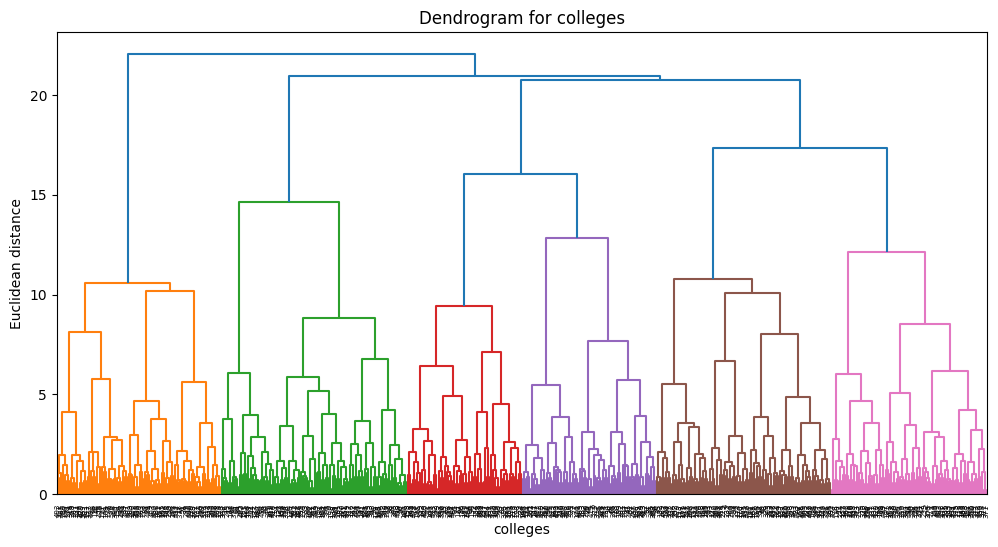

In [16]:
plt.figure(figsize=(12,6))
dendrogram = sch.dendrogram(sch.linkage(scaled_X, method='ward'))
plt.xlabel("colleges")
plt.ylabel("Euclidean distance")
plt.title("Dendrogram for colleges")

### check with some colleges for better view

Text(0.5, 1.0, 'Dendrogram for colleges')

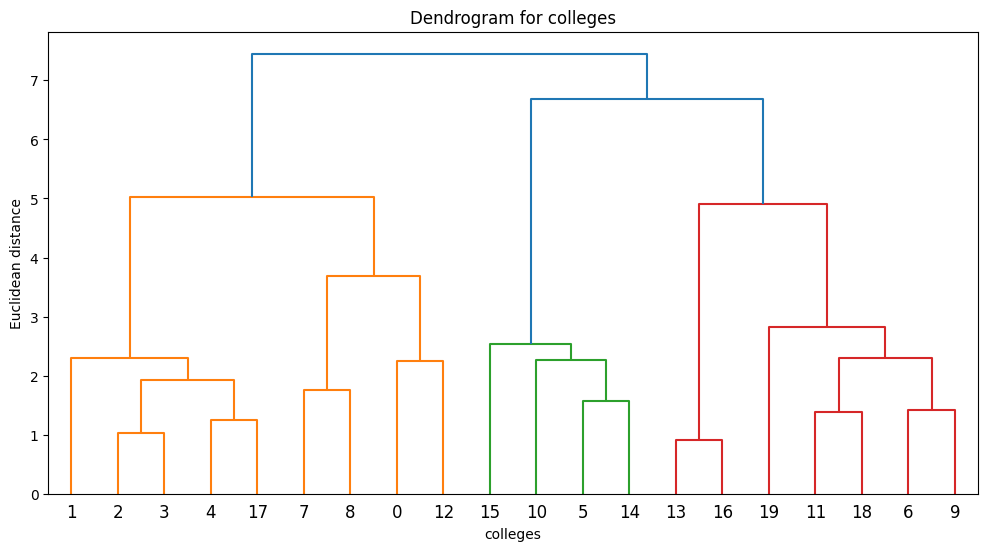

In [17]:
X_test = scaled_X.head(20)
plt.figure( figsize=(12,6))
dendrogram = sch.dendrogram(sch.linkage(X_test, method='ward'))
plt.xlabel("colleges")
plt.ylabel("Euclidean distance")
plt.title("Dendrogram for colleges")

In [21]:
hc = AgglomerativeClustering( n_clusters=3, metric='euclidean',linkage='ward')
clusters = hc.fit_predict(scaled_X)
clusters

array([2, 0, 0, 0, 0, 0, 1, 0, 2, 1, 0, 1, 0, 2, 0, 0, 2, 0, 1, 1, 0, 2,
       2, 0, 1, 0, 0, 0, 0, 0, 0, 2, 1, 2, 2, 0, 1, 0, 2, 1, 0, 1, 0, 0,
       2, 0, 1, 0, 0, 0, 0, 1, 0, 2, 0, 0, 2, 0, 0, 2, 2, 2, 0, 0, 2, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 2, 1, 0, 2,
       0, 2, 2, 2, 0, 0, 0, 0, 0, 2, 1, 2, 2, 1, 0, 0, 2, 2, 0, 1, 1, 2,
       0, 2, 1, 0, 0, 0, 0, 1, 2, 0, 0, 0, 2, 2, 0, 0, 2, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 2, 2, 2, 2, 0, 0, 2, 0, 1, 0, 0, 2, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 2, 2, 2, 0, 0, 0, 0, 0, 0, 2, 1, 0, 2, 1, 0, 0, 0, 0,
       2, 0, 0, 1, 1, 2, 0, 2, 1, 0, 1, 1, 0, 2, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 1, 2, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 2, 2,
       0, 0, 2, 2, 1, 0, 0, 0, 1, 0, 1, 0, 0, 2, 0, 1, 1, 1, 0, 2, 0, 0,
       1, 0, 0, 1, 0, 0, 2, 1, 0, 1, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 2, 0, 0, 1, 0, 0, 0, 2, 0, 1, 0, 0, 1, 0,

# Level 2 - Attach clusters to the Dataset

## 1. Attach clusters to the dataset

In [26]:
college_data["College_level"] = clusters
college_data

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College level,College_level
0,Indian Institute of Technology Madras - Campus 1,14,113042,59,9.20,8,2,2
1,National Institute of Technology Trichy - Camp...,27,115999,67,3.07,7,0,0
2,Anna University Chennai - Campus 1,22,47955,50,3.40,9,0,0
3,PSG College of Technology - Campus 1,18,67841,43,4.64,8,0,0
4,Coimbatore Institute of Technology - Campus 1,15,100640,54,4.66,9,0,0
...,...,...,...,...,...,...,...,...
495,Thiagarajar College of Engineering - Campus 17,17,106323,56,9.33,5,0,0
496,Bannari Amman Institute of Technology - Campus 17,12,39111,76,3.62,7,0,0
497,Sri Krishna College of Engineering and Technol...,16,199182,64,3.88,3,1,1
498,Sona College of Technology - Campus 17,10,46389,77,9.31,6,0,0


## 2. Data understanding - Analyze the clusters

In [27]:
college_data[college_data["College_level"] == 0]

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College level,College_level
1,National Institute of Technology Trichy - Camp...,27,115999,67,3.07,7,0,0
2,Anna University Chennai - Campus 1,22,47955,50,3.40,9,0,0
3,PSG College of Technology - Campus 1,18,67841,43,4.64,8,0,0
4,Coimbatore Institute of Technology - Campus 1,15,100640,54,4.66,9,0,0
5,Government College of Technology Coimbatore - ...,28,226582,45,9.32,4,0,0
...,...,...,...,...,...,...,...,...
494,Kumaraguru College of Technology - Campus 17,11,34324,73,11.40,3,0,0
495,Thiagarajar College of Engineering - Campus 17,17,106323,56,9.33,5,0,0
496,Bannari Amman Institute of Technology - Campus 17,12,39111,76,3.62,7,0,0
498,Sona College of Technology - Campus 17,10,46389,77,9.31,6,0,0


In [28]:
X["College_level"] = clusters
X

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College level,College_level
0,14,113042,59,9.20,8,2,2
1,27,115999,67,3.07,7,0,0
2,22,47955,50,3.40,9,0,0
3,18,67841,43,4.64,8,0,0
4,15,100640,54,4.66,9,0,0
...,...,...,...,...,...,...,...
495,17,106323,56,9.33,5,0,0
496,12,39111,76,3.62,7,0,0
497,16,199182,64,3.88,3,1,1
498,10,46389,77,9.31,6,0,0


In [30]:
X.groupby(by="College_level").agg(["mean"])

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College level
,mean,mean,mean,mean,mean,mean
College_level,,,,,,
0,20.407051,121853.471154,67.278846,6.954583,6.509615,0.0
1,17.159091,156795.136364,85.568182,5.565682,3.965909,1.0
2,11.650000,175656.000000,59.790000,8.362500,6.080000,2.0


In [31]:
X.groupby(by="College_level").agg(["min","max"])

Student_Faculty_Ratio     Annual_Fees_INR          ... Infrastructure_Score     College level    
                                min max             min     max  ...                  min max           min max
College_level                                                    ...                                           
0                                 8  29           30404  249536  ...                    3   9             0   0
1                                 8  29           39337  248803  ...                    3   9             1   1
2                                 8  20           49065  249930  ...                    3   9             2   2

[3 rows x 12 columns]

In [32]:
cluster_names = { 0:"Mid_level",
                  1:"Best_level",
                  2:"Emerging_level"}
X["Category"] = X["College_level"].map(cluster_names)
X

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College level,College_level,Category
0,14,113042,59,9.20,8,2,2,Emerging_level
1,27,115999,67,3.07,7,0,0,Mid_level
2,22,47955,50,3.40,9,0,0,Mid_level
3,18,67841,43,4.64,8,0,0,Mid_level
4,15,100640,54,4.66,9,0,0,Mid_level
...,...,...,...,...,...,...,...,...
495,17,106323,56,9.33,5,0,0,Mid_level
496,12,39111,76,3.62,7,0,0,Mid_level
497,16,199182,64,3.88,3,1,1,Best_level
498,10,46389,77,9.31,6,0,0,Mid_level


# Level 3: Transition to supervised learning

In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [40]:
input_data = X.drop(["College_level","Category"],axis=1)
output_data = X["College_level"]

X_train,X_test,y_train,y_test = train_test_split(input_data,output_data,test_size=0.20,random_state=123,shuffle=True,stratify=output_data)

model = RandomForestClassifier()
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

print("Accuracy score:",accuracy_score(y_test,y_pred))

Accuracy score: 1.0


## Take the model to add in the backend

In [41]:
from pickle import dump

In [43]:
dump(model,open("College_category_model.pkl","wb"))

## the end!!